# UrbanLens
## Descubrimiento no supervisado de patrones visuales urbanos

**Curso:** Inteligencia Artificial  
**Semana 6:** Métodos no supervisados  
**Entorno:** Google Colab + Google Drive  

### Objetivo
Construir un flujo reproducible de aprendizaje no supervisado que agrupe imágenes urbanas por similitud visual, sin utilizar etiquetas de clase.

### Pipeline
1. Cargar imágenes propias desde Google Drive.
2. Validar y explorar el dataset.
3. Extraer características visuales con **MobileNetV2** preentrenada.
4. Normalizar los embeddings.
5. Reducir dimensionalidad mediante **PCA**.
6. Evaluar distintos valores de **K** con *Silhouette Score* e inercia.
7. Entrenar **K-Means**.
8. Visualizar e interpretar los clusters.
9. Identificar imágenes representativas de cada cluster.
10. Exportar resultados a Google Drive.

> **Importante:** MobileNetV2 se utiliza únicamente como extractor de características.  
> El agrupamiento sigue siendo **no supervisado**, porque K-Means no recibe etiquetas.

## 1. Montar Google Drive

Al ejecutar esta celda, Colab solicitará autorización para acceder a su Google Drive.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')
print("✅ Google Drive montado correctamente.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Google Drive montado correctamente.


## 2. Configuración general

La carpeta esperada es:

```text
Mi unidad/
└── UrbanLens/
    └── dataset/
        ├── img001.jpg
        ├── img002.jpg
        └── ...
```

El notebook también detecta automáticamente la variante `Dataser` por si la carpeta todavía conserva ese nombre.

In [ ]:
from pathlib import Path

# =========================
# CONFIGURACIÓN DEL PROYECTO
# =========================

PROJECT_DIR = Path("/content/drive/MyDrive/UrbanLens")

# Se buscará la primera carpeta existente de esta lista.
DATASET_CANDIDATES = ["dataset", "Dataset"]

RESULTS_DIR = PROJECT_DIR / "resultados"
CACHE_DIR = PROJECT_DIR / "cache"

# Configuración del procesamiento
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# K-Means
MAX_K_TO_EVALUATE = 8

# Si es None, se selecciona automáticamente el K con mejor Silhouette Score.
# Si desea forzar un K concreto, por ejemplo 4, cambie a: MANUAL_K = 4
MANUAL_K = None

# Cantidad máxima de imágenes que se muestran por cluster.
MAX_IMAGES_PER_CLUSTER = 12

# Cantidad de imágenes más representativas por cluster.
N_REPRESENTATIVE_IMAGES = 5

# Formatos admitidos
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

# Crear carpetas de salida
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("Proyecto:", PROJECT_DIR)
print("Resultados:", RESULTS_DIR)
print("Caché:", CACHE_DIR)

Proyecto: /content/drive/MyDrive/UrbanLens
Resultados: /content/drive/MyDrive/UrbanLens/resultados
Caché: /content/drive/MyDrive/UrbanLens/cache


## 3. Localizar y verificar el dataset

In [ ]:
dataset_path = None

for folder_name in DATASET_CANDIDATES:
    candidate = PROJECT_DIR / folder_name
    if candidate.exists() and candidate.is_dir():
        dataset_path = candidate
        break

if dataset_path is None:
    raise FileNotFoundError(
        " No se encontró la carpeta del dataset.\n"
        f"Revise que exista alguna de estas rutas:\n"
        + "\n".join(str(PROJECT_DIR / name) for name in DATASET_CANDIDATES)
    )

print(" Dataset encontrado en:")
print(dataset_path)

 Dataset encontrado en:
/content/drive/MyDrive/UrbanLens/Dataset


## 4. Importar librerías y fijar semilla

La semilla facilita la reproducibilidad de los resultados.

In [ ]:
import os
import random
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
from IPython.display import display

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.utils import load_img, img_to_array

from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(" Librerías cargadas.")
print("TensorFlow:", tf.__version__)

 Librerías cargadas.
TensorFlow: 2.20.0


## 5. Inventario y validación de imágenes

Esta sección:
- busca imágenes incluso dentro de subcarpetas;
- verifica que puedan abrirse;
- separa archivos válidos y dañados;
- muestra estadísticas básicas del dataset.

In [ ]:
all_image_paths = sorted([
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
])

if len(all_image_paths) == 0:
    raise ValueError("❌ No se encontraron imágenes compatibles en el dataset.")

valid_image_paths = []
corrupted_images = []

for path in all_image_paths:
    try:
        with Image.open(path) as img:
            img.verify()
        valid_image_paths.append(path)
    except Exception as e:
        corrupted_images.append((str(path), str(e)))

print(f" Imágenes encontradas: {len(all_image_paths)}")
print(f" Imágenes válidas: {len(valid_image_paths)}")
print(f" Imágenes dañadas/no legibles: {len(corrupted_images)}")

if corrupted_images:
    display(pd.DataFrame(corrupted_images, columns=["archivo", "error"]).head(20))

if len(valid_image_paths) < 3:
    raise ValueError("Se necesitan al menos 3 imágenes válidas para realizar clustering y evaluación.")

if len(valid_image_paths) < 50:
    print(" Advertencia: el flujo funcionará, pero un dataset mayor suele producir análisis más representativos.")

 Imágenes encontradas: 30
 Imágenes válidas: 30
 Imágenes dañadas/no legibles: 0
 Advertencia: el flujo funcionará, pero un dataset mayor suele producir análisis más representativos.


## 6. Resumen del dataset

In [ ]:
rows = []

for path in valid_image_paths:
    with Image.open(path) as img:
        width, height = img.size
        rows.append({
            "archivo": path.name,
            "ruta": str(path),
            "ancho_px": width,
            "alto_px": height,
            "formato": img.format,
            "modo": img.mode
        })

df_images = pd.DataFrame(rows)

display(df_images.head())

print("\nResumen de dimensiones:")
display(df_images[["ancho_px", "alto_px"]].describe().round(2))

,archivo,ruta,ancho_px,alto_px,formato,modo
0,imagen1.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,2250,3362,JPEG,RGB
1,imagen10.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,4096,1840,JPEG,RGB
2,imagen11.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,4032,3024,JPEG,RGB
3,imagen12.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,3648,2736,MPO,RGB
4,imagen13.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,1122,841,JPEG,RGB



Resumen de dimensiones:


,ancho_px,alto_px
count,30.00,30.00
mean,3595.57,2500.03
std,1656.92,1161.82
min,1122.00,841.00
25%,2594.00,1691.25
50%,3456.00,2448.00
75%,4032.00,3024.00
max,7952.00,5304.00


## 7. Mostrar una muestra aleatoria de imágenes

Esto permite comprobar visualmente que el dataset contiene diversidad suficiente.

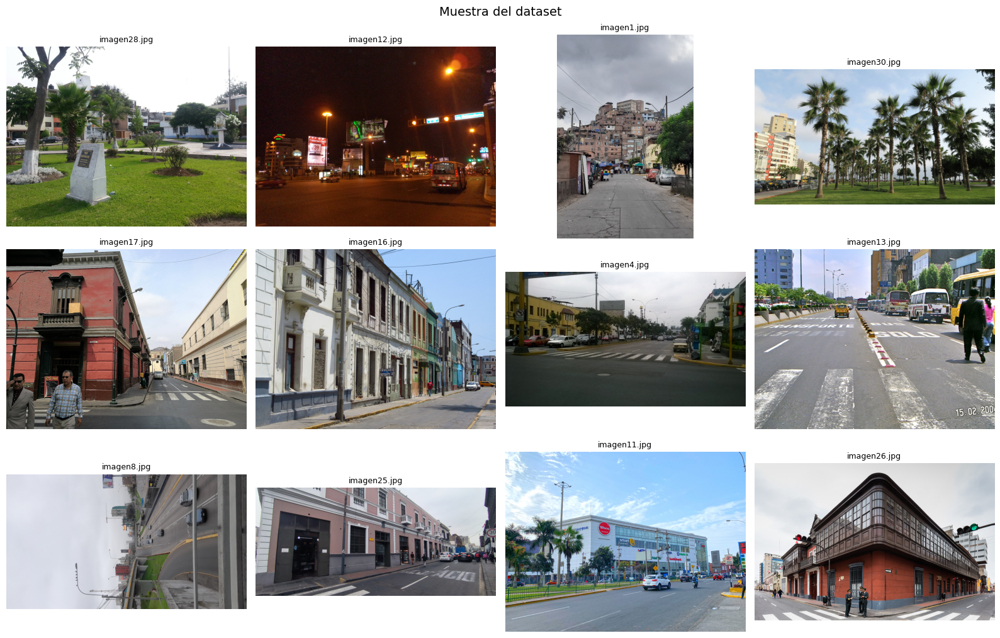

In [ ]:
def show_image_grid(paths, title="Muestra del dataset", max_images=12, seed=SEED):
    paths = list(paths)
    if not paths:
        print("No hay imágenes para mostrar.")
        return

    rng = random.Random(seed)
    selected = rng.sample(paths, min(max_images, len(paths)))

    n = len(selected)
    cols = min(4, n)
    rows = int(np.ceil(n / cols))

    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))
    axes = np.atleast_1d(axes).ravel()

    for ax, path in zip(axes, selected):
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(path.name, fontsize=9)
        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

show_image_grid(valid_image_paths, max_images=12)

## 8. Construir el extractor de características MobileNetV2

Se usa **MobileNetV2 preentrenada en ImageNet**, eliminando su clasificador final (`include_top=False`) y aplicando *global average pooling* (`pooling='avg'`).

Cada imagen se transforma en un **embedding de 1280 características**.

In [ ]:
feature_extractor = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)
)

feature_extractor.trainable = False

print(" MobileNetV2 preparada como extractor de características.")
print("Dimensión esperada del embedding:", feature_extractor.output_shape[-1])

 MobileNetV2 preparada como extractor de características.
Dimensión esperada del embedding: 1280


## 9. Extraer embeddings visuales

Para ahorrar tiempo en ejecuciones futuras, los embeddings se guardan en caché dentro de Drive.  
La caché solo se reutiliza si contiene exactamente la misma lista de imágenes.

In [ ]:
CACHE_FILE = CACHE_DIR / "mobilenetv2_embeddings.npz"

current_files = np.array([str(p) for p in valid_image_paths])

def extract_features(image_paths, model, batch_size=32):
    all_features = []

    for start in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[start:start + batch_size]
        batch_images = []

        for path in batch_paths:
            img = load_img(path, target_size=IMAGE_SIZE)
            arr = img_to_array(img)
            batch_images.append(arr)

        batch_array = np.stack(batch_images).astype(np.float32)
        batch_array = preprocess_input(batch_array)

        batch_features = model.predict(batch_array, verbose=0)
        all_features.append(batch_features)

        processed = min(start + batch_size, len(image_paths))
        print(f"Procesadas: {processed}/{len(image_paths)}", end="\r")

    print()
    return np.vstack(all_features)


use_cache = False

if CACHE_FILE.exists():
    try:
        cache = np.load(CACHE_FILE, allow_pickle=True)
        cached_files = cache["files"]
        cached_features = cache["features"]

        if np.array_equal(cached_files, current_files):
            features = cached_features
            use_cache = True
            print("✅ Embeddings cargados desde la caché.")
        else:
            print("ℹ️ El dataset cambió. Se recalcularán los embeddings.")
    except Exception:
        print("ℹ️ La caché no pudo reutilizarse. Se recalcularán los embeddings.")

if not use_cache:
    features = extract_features(
        valid_image_paths,
        feature_extractor,
        batch_size=BATCH_SIZE
    )

    np.savez_compressed(
        CACHE_FILE,
        files=current_files,
        features=features
    )

    print(" Embeddings calculados y guardados en caché.")

print("Forma de la matriz de características:", features.shape)

✅ Embeddings cargados desde la caché.
Forma de la matriz de características: (30, 1280)


## 10. Normalizar embeddings

Se aplica normalización L2 a cada embedding. Esto evita que la magnitud del vector domine la comparación y hace que la similitud visual dependa principalmente de su dirección en el espacio de características.

In [ ]:
X_normalized = normalize(features, norm="l2")

print(" Embeddings normalizados.")
print("Matriz:", X_normalized.shape)
print("Norma del primer vector:", np.linalg.norm(X_normalized[0]).round(4))

 Embeddings normalizados.
Matriz: (30, 1280)
Norma del primer vector: 1.0


## 11. Reducción dimensional con PCA

Se conserva aproximadamente el **95 % de la varianza** para:
- reducir ruido y redundancia;
- disminuir el costo del clustering;
- mantener la mayor parte de la información de los embeddings.

In [ ]:
pca_cluster = PCA(
    n_components=0.95,
    svd_solver="full"
)

X_cluster = pca_cluster.fit_transform(X_normalized)

explained_variance = pca_cluster.explained_variance_ratio_.sum()

print(" PCA aplicado.")
print("Dimensiones originales:", X_normalized.shape[1])
print("Dimensiones después de PCA:", X_cluster.shape[1])
print(f"Varianza explicada acumulada: {explained_variance:.2%}")

 PCA aplicado.
Dimensiones originales: 1280
Dimensiones después de PCA: 26
Varianza explicada acumulada: 96.09%


## 12. Evaluar automáticamente diferentes valores de K

Se utilizan dos indicadores:

- **Silhouette Score:** mide cohesión interna y separación entre clusters. Valores mayores suelen indicar una estructura más clara.
- **Inercia:** suma de distancias cuadráticas de las muestras a sus centroides. Disminuye al aumentar K y es útil para observar el llamado *método del codo*.

La selección automática utilizará el **K con mayor Silhouette Score** dentro del rango evaluado.

In [ ]:
n_samples = X_cluster.shape[0]

max_valid_k = min(MAX_K_TO_EVALUATE, n_samples - 1)

if max_valid_k < 2:
    raise ValueError("No hay suficientes imágenes para evaluar K-Means.")

candidate_ks = list(range(2, max_valid_k + 1))

evaluation_rows = []

for k in candidate_ks:
    model = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=10
    )

    labels_k = model.fit_predict(X_cluster)

    sil = silhouette_score(X_cluster, labels_k)

    evaluation_rows.append({
        "K": k,
        "Silhouette_Score": sil,
        "Inercia": model.inertia_
    })

evaluation_df = pd.DataFrame(evaluation_rows)

display(
    evaluation_df.style.format({
        "Silhouette_Score": "{:.4f}",
        "Inercia": "{:.2f}"
    })
)

best_k_auto = int(
    evaluation_df.loc[evaluation_df["Silhouette_Score"].idxmax(), "K"]
)

best_sil_auto = float(
    evaluation_df["Silhouette_Score"].max()
)

print(f"\n Mejor K automático: {best_k_auto}")
print(f"Silhouette Score: {best_sil_auto:.4f}")

,K,Silhouette_Score,Inercia
0,2,0.0589,12.77
1,3,0.0666,11.94
2,4,0.0538,11.07
3,5,0.0248,10.62
4,6,0.0509,9.74
5,7,0.0581,9.06
6,8,0.0405,8.67



 Mejor K automático: 3
Silhouette Score: 0.0666


### 12.1 Gráfico de Silhouette Score

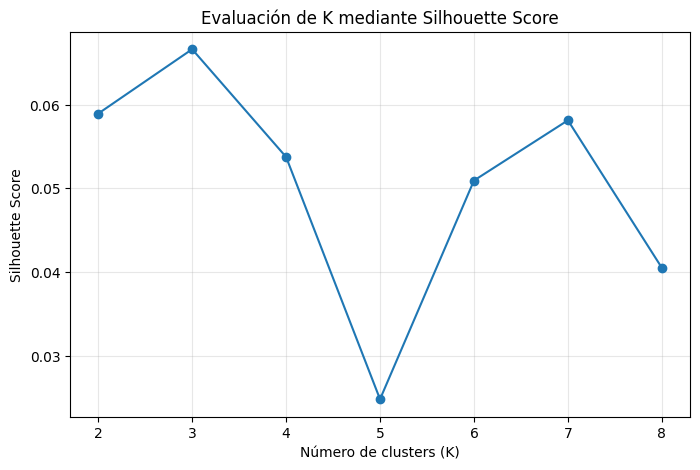

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(
    evaluation_df["K"],
    evaluation_df["Silhouette_Score"],
    marker="o"
)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Evaluación de K mediante Silhouette Score")
plt.xticks(evaluation_df["K"])
plt.grid(alpha=0.3)
plt.show()

### 12.2 Gráfico de inercia

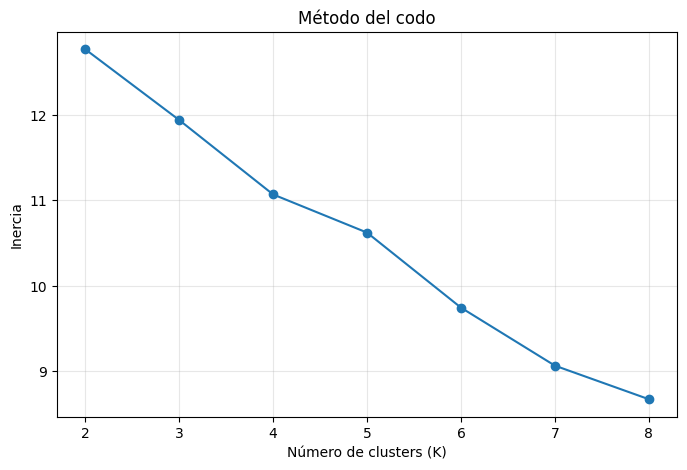

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(
    evaluation_df["K"],
    evaluation_df["Inercia"],
    marker="o"
)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.xticks(evaluation_df["K"])
plt.grid(alpha=0.3)
plt.show()

## 13. Seleccionar K y entrenar el modelo final

- Si `MANUAL_K = None`, se usa automáticamente el mejor K según Silhouette Score.
- Si desea experimentar con otro valor, vuelva a la sección de configuración y establezca, por ejemplo, `MANUAL_K = 4`.

In [ ]:
if MANUAL_K is None:
    SELECTED_K = best_k_auto
else:
    SELECTED_K = int(MANUAL_K)

    if not (2 <= SELECTED_K < n_samples):
        raise ValueError(
            f"MANUAL_K debe estar entre 2 y {n_samples - 1}."
        )

kmeans = KMeans(
    n_clusters=SELECTED_K,
    random_state=SEED,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster)
final_silhouette = silhouette_score(X_cluster, cluster_labels)

print("✅ Modelo K-Means final entrenado.")
print("K seleccionado:", SELECTED_K)
print(f"Silhouette Score final: {final_silhouette:.4f}")

✅ Modelo K-Means final entrenado.
K seleccionado: 3
Silhouette Score final: 0.0666


## 14. Distribución de imágenes por cluster

In [ ]:
cluster_counts = (
    pd.Series(cluster_labels, name="cluster")
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="cantidad_imagenes")
)

cluster_counts["porcentaje"] = (
    cluster_counts["cantidad_imagenes"] / len(cluster_labels) * 100
)

display(
    cluster_counts.style.format({
        "porcentaje": "{:.2f}%"
    })
)

,cluster,cantidad_imagenes,porcentaje
0,0,10,33.33%
1,1,18,60.00%
2,2,2,6.67%


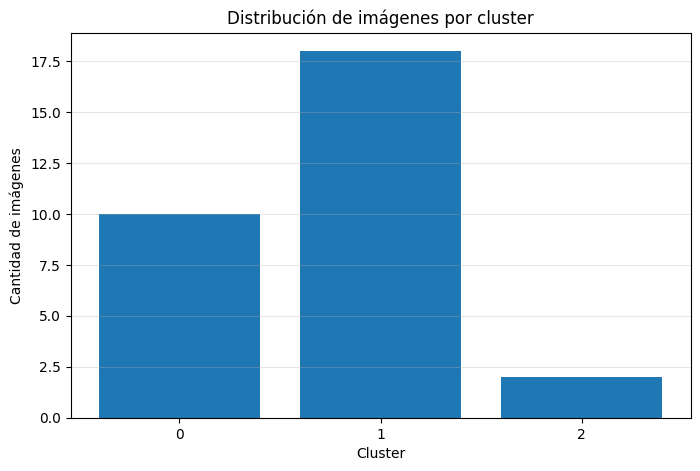

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(
    cluster_counts["cluster"].astype(str),
    cluster_counts["cantidad_imagenes"]
)
plt.xlabel("Cluster")
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de imágenes por cluster")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 15. Visualización bidimensional de los clusters

Para visualizar el espacio de imágenes se aplica un segundo PCA de **2 dimensiones**.  
Este PCA es exclusivamente para representación gráfica y no reemplaza el PCA utilizado durante el clustering.

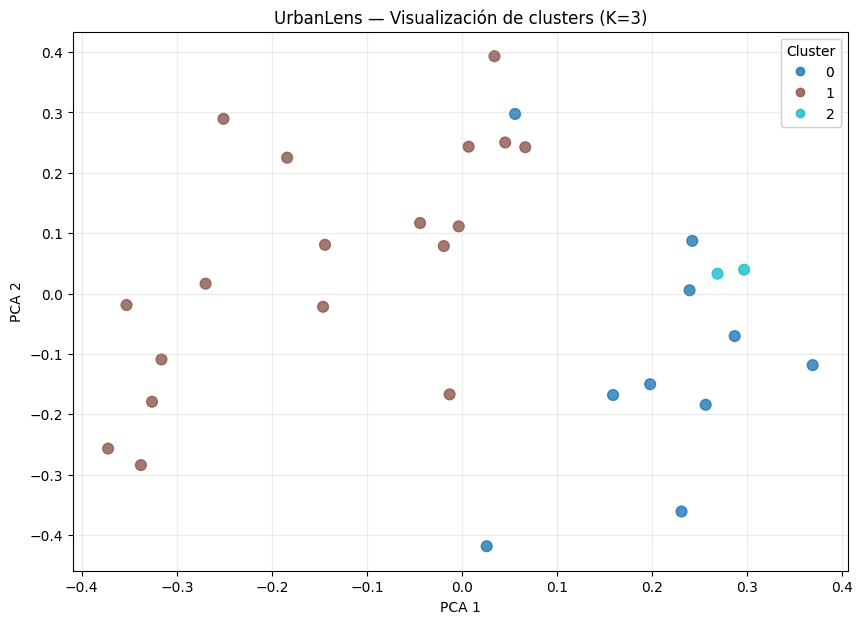

Varianza explicada por la proyección 2D: 18.70%


In [ ]:
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_normalized)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=cluster_labels,
    cmap="tab10",
    s=60,
    alpha=0.8
)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title(f"UrbanLens — Visualización de clusters (K={SELECTED_K})")
plt.grid(alpha=0.25)

legend = plt.legend(
    *scatter.legend_elements(),
    title="Cluster",
    loc="best"
)
plt.gca().add_artist(legend)

plt.show()

print(
    f"Varianza explicada por la proyección 2D: "
    f"{pca_2d.explained_variance_ratio_.sum():.2%}"
)

## 16. Galería visual por cluster

Esta es una de las secciones más importantes para la interpretación.  
Observe qué características se repiten dentro de cada grupo: vegetación, densidad de edificios, tráfico, amplitud de vía, comercio, iluminación, materiales, colores, etc.

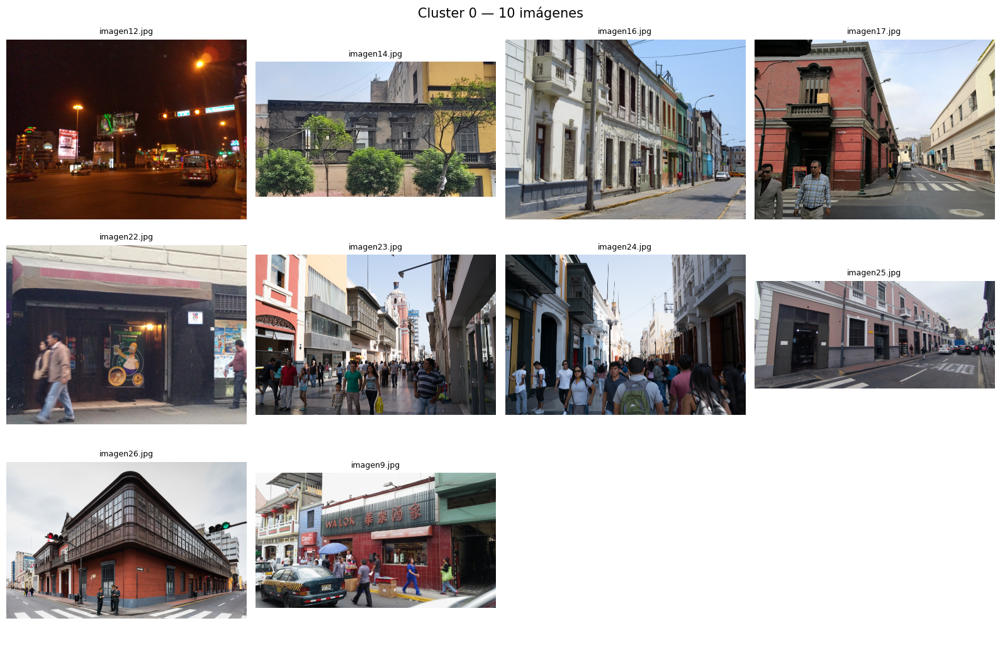

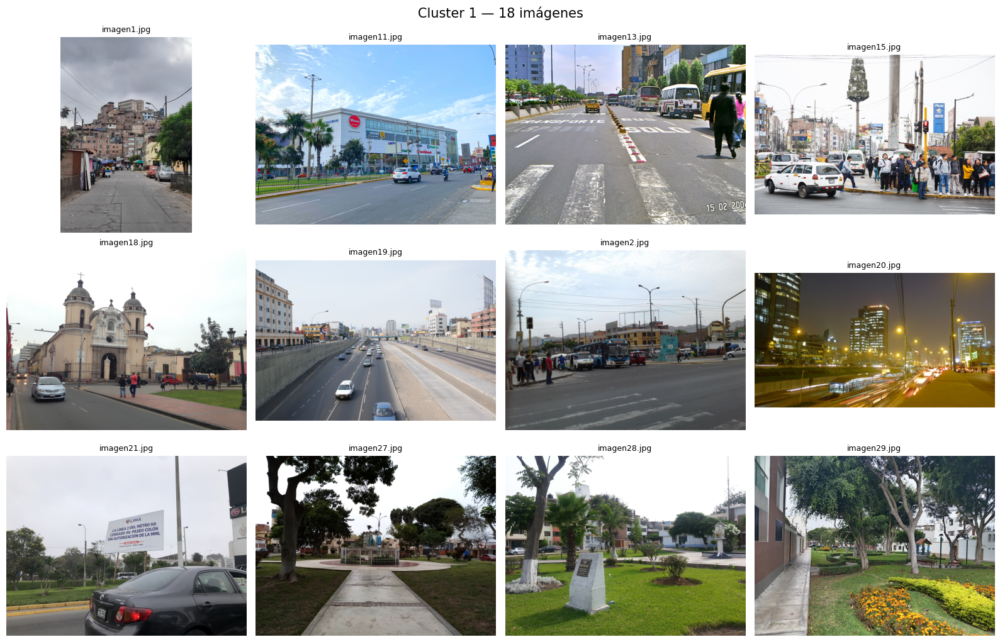

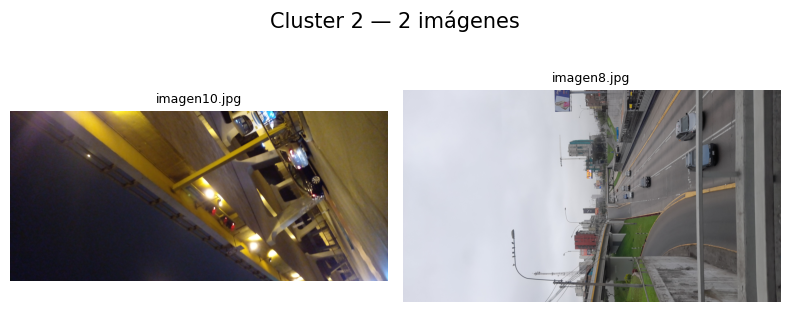

In [ ]:
def show_cluster_gallery(
    image_paths,
    labels,
    max_images_per_cluster=12
):
    labels = np.asarray(labels)

    for cluster_id in sorted(np.unique(labels)):
        indices = np.where(labels == cluster_id)[0]
        selected_indices = indices[:max_images_per_cluster]

        n = len(selected_indices)
        cols = min(4, n)
        rows = int(np.ceil(n / cols))

        fig, axes = plt.subplots(
            rows,
            cols,
            figsize=(4 * cols, 3.5 * rows)
        )
        axes = np.atleast_1d(axes).ravel()

        for ax, idx in zip(axes, selected_indices):
            path = image_paths[idx]

            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(path.name, fontsize=9)
            ax.axis("off")

        for ax in axes[len(selected_indices):]:
            ax.axis("off")

        fig.suptitle(
            f"Cluster {cluster_id} — {len(indices)} imágenes",
            fontsize=15
        )

        plt.tight_layout()
        plt.show()


show_cluster_gallery(
    valid_image_paths,
    cluster_labels,
    max_images_per_cluster=MAX_IMAGES_PER_CLUSTER
)

## 17. Imágenes más representativas de cada cluster

Se calculan las imágenes más cercanas al centroide de cada cluster en el espacio utilizado por K-Means.

Estas imágenes pueden utilizarse como **prototipos visuales** para interpretar el significado del grupo.


Cluster 0 — imágenes representativas


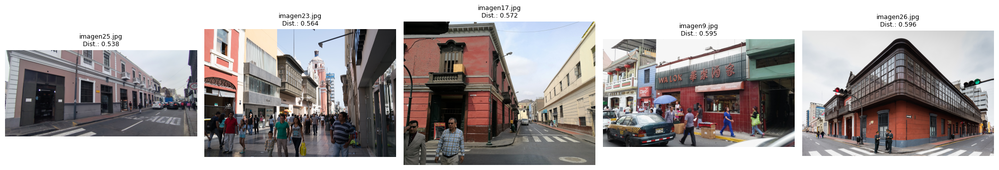


Cluster 1 — imágenes representativas


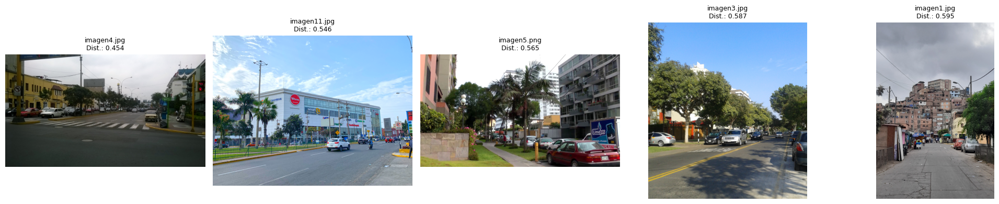


Cluster 2 — imágenes representativas


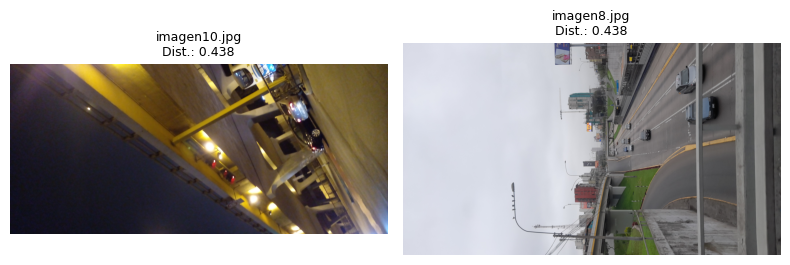

,cluster,archivo,ruta,distancia_centroide
0,0,imagen25.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,0.537756
1,0,imagen23.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,0.564072
2,0,imagen17.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,0.571689
3,0,imagen9.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,0.594807
4,0,imagen26.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,0.595617
5,1,imagen4.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,0.454438
6,1,imagen11.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,0.546444
7,1,imagen5.png,/content/drive/MyDrive/UrbanLens/Dataset/image...,0.564899
8,1,imagen3.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,0.586771
9,1,imagen1.jpg,/content/drive/MyDrive/UrbanLens/Dataset/image...,0.595133


In [ ]:
distances = kmeans.transform(X_cluster)

representative_records = []

for cluster_id in range(SELECTED_K):
    cluster_indices = np.where(cluster_labels == cluster_id)[0]

    sorted_indices = sorted(
        cluster_indices,
        key=lambda idx: distances[idx, cluster_id]
    )

    representative_indices = sorted_indices[:N_REPRESENTATIVE_IMAGES]

    print(f"\nCluster {cluster_id} — imágenes representativas")

    cols = len(representative_indices)
    fig, axes = plt.subplots(
        1,
        cols,
        figsize=(4 * cols, 4)
    )
    axes = np.atleast_1d(axes).ravel()

    for ax, idx in zip(axes, representative_indices):
        path = valid_image_paths[idx]

        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"{path.name}\nDist.: {distances[idx, cluster_id]:.3f}",
            fontsize=9
        )
        ax.axis("off")

        representative_records.append({
            "cluster": cluster_id,
            "archivo": path.name,
            "ruta": str(path),
            "distancia_centroide": distances[idx, cluster_id]
        })

    plt.tight_layout()
    plt.show()

representative_df = pd.DataFrame(representative_records)
display(representative_df)

## 18. Plantilla de interpretación académica

Complete esta sección **después de observar las galerías**, porque el algoritmo no conoce categorías semánticas.

### Cluster 0
- Características visuales predominantes:
- Posible interpretación urbana:
- Excepciones o imágenes que no encajan claramente:

### Cluster 1
- Características visuales predominantes:
- Posible interpretación urbana:
- Excepciones o imágenes que no encajan claramente:

### Cluster 2
- Características visuales predominantes:
- Posible interpretación urbana:
- Excepciones o imágenes que no encajan claramente:

> Agregue o elimine apartados según el número de clusters seleccionado.

### Preguntas para la discusión
1. ¿Los clusters obtenidos presentan coherencia visual?
2. ¿Qué factores parecen influir más: vegetación, edificios, tráfico, iluminación u otros?
3. ¿Existen imágenes ambiguas entre dos grupos?
4. ¿El valor de K elegido por Silhouette Score coincide con la interpretación humana?
5. ¿Qué limitaciones introduce utilizar MobileNetV2, entrenada originalmente con ImageNet?
6. ¿Cómo podrían cambiar los resultados si se amplía el dataset?

## 19. Conclusiones sugeridas para el laboratorio

Al redactar sus propias conclusiones, considere distinguir claramente entre resultados observados y generalizaciones.

Puntos que sí puede discutir:

- UrbanLens agrupa imágenes sin utilizar etiquetas de clase.
- MobileNetV2 actúa como extractor de representaciones visuales y K-Means realiza el agrupamiento.
- PCA reduce la dimensionalidad y facilita tanto el clustering como la visualización.
- Silhouette Score aporta un criterio cuantitativo para comparar valores de K.
- La inspección de galerías es necesaria para interpretar semánticamente los clusters.
- El resultado depende de la diversidad, calidad y cantidad de fotografías disponibles.

### Limitaciones
- K-Means supone clusters aproximadamente compactos en el espacio de características.
- Los embeddings dependen del conocimiento aprendido previamente por MobileNetV2.
- PCA 2D es una proyección y puede ocultar relaciones existentes en dimensiones superiores.
- Un dataset pequeño o poco diverso puede producir agrupamientos poco estables.
- La interpretación de cada cluster sigue siendo realizada por personas.

### Posibles mejoras futuras
- Comparar K-Means con DBSCAN o clustering jerárquico.
- Utilizar otros extractores de características.
- Aumentar el número y diversidad de imágenes urbanas.
- Incorporar reducción dimensional no lineal para exploración visual.
- Analizar la estabilidad de los clusters bajo diferentes muestras del dataset.